# Hyperparameter Tuning — Breast Cancer Classification

## Objectives
- Understand Logistic Regression regularization.
- Explore the impact of C.
- Perform GridSearchCV.
- Compare CV performance across configurations.
- Optimize malignant recall.
- Evaluate the selected model on the test set.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    make_scorer,
    recall_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    f1_score
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300

In [3]:
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (455, 30)
Testing shape: (114, 30)


In [4]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L

In [5]:
param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

param_grid

{'model__C': [0.001, 0.01, 0.1, 1, 10, 100]}

In [6]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

malignant_recall_scorer = make_scorer(
    recall_score,
    pos_label=0
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "malignant_recall": malignant_recall_scorer
}

In [7]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="malignant_recall",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1_macro': 'f1_macro', 'malignant_recall': make_scorer(r..., pos_label=0), 'precision_macro': 'precision_macro', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'malignant_recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` 

In [8]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV Malignant Recall:")
print(grid_search.best_score_)

Best Parameters:
{'model__C': 1}

Best CV Malignant Recall:
0.9647058823529411


In [9]:
results_df = pd.DataFrame(grid_search.cv_results_)

results_df = results_df[
    [
        "param_model__C",
        "mean_test_accuracy",
        "std_test_accuracy",
        "mean_test_f1_macro",
        "mean_test_malignant_recall",
        "std_test_malignant_recall",
        "mean_train_malignant_recall"
    ]
]

results_df = results_df.sort_values(
    "mean_test_malignant_recall",
    ascending=False
)

results_df

,param_model__C,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro,mean_test_malignant_recall,std_test_malignant_recall,mean_train_malignant_recall
3,1.000,0.978022,0.009829,0.976426,0.964706,0.028818,0.976471
2,0.100,0.982418,0.005383,0.981071,0.958824,0.014409,0.969118
5,100.000,0.953846,0.016150,0.950718,0.941176,0.041595,0.991176
4,10.000,0.962637,0.011207,0.959803,0.935294,0.028818,0.982353
1,0.010,0.951648,0.014906,0.946646,0.870588,0.039896,0.879412
0,0.001,0.885714,0.029157,0.867480,0.700000,0.075331,0.692647


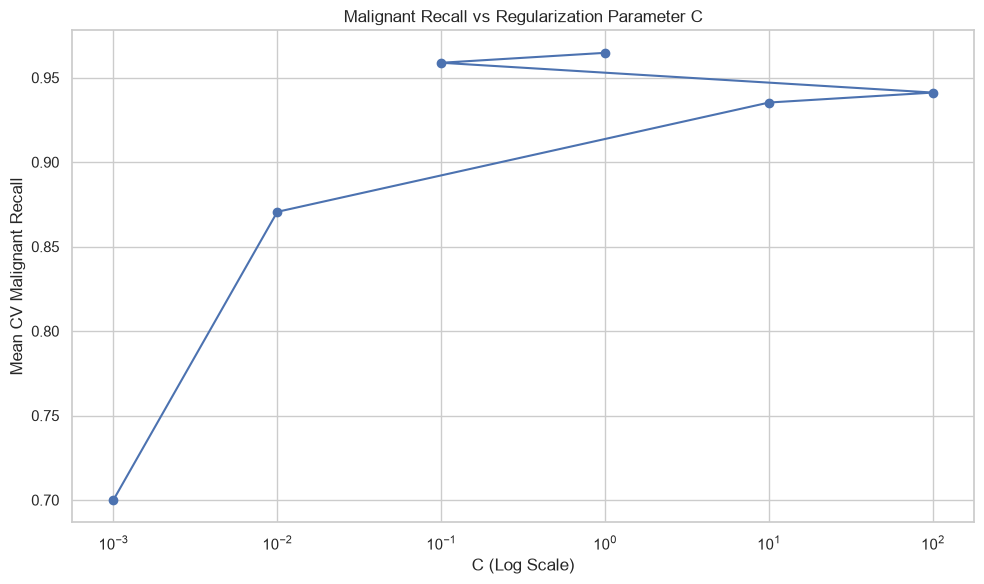

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["param_model__C"].astype(float),
    results_df["mean_test_malignant_recall"],
    marker="o"
)

plt.xscale("log")

plt.title("Malignant Recall vs Regularization Parameter C")
plt.xlabel("C (Log Scale)")
plt.ylabel("Mean CV Malignant Recall")

plt.tight_layout()
plt.show()

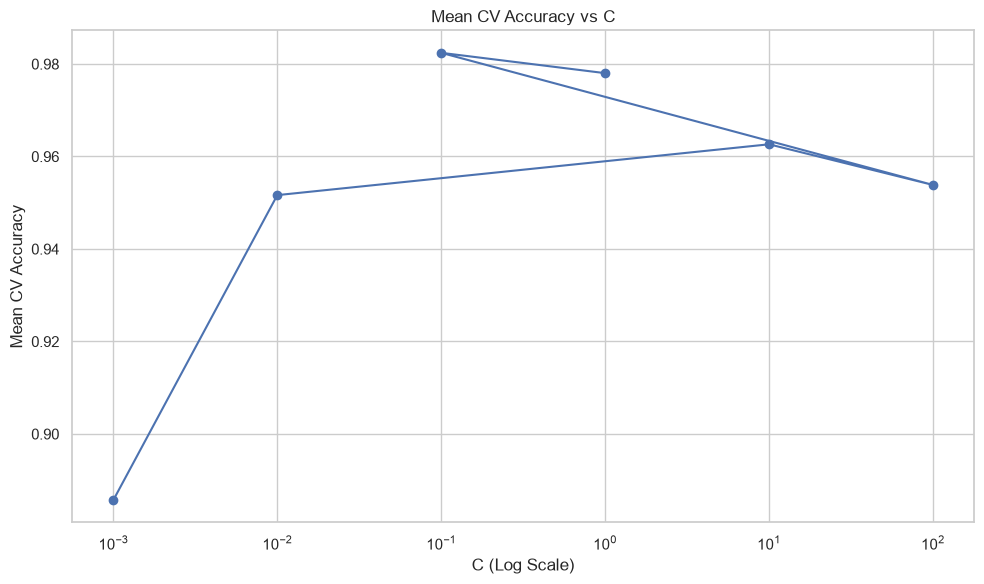

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["param_model__C"].astype(float),
    results_df["mean_test_accuracy"],
    marker="o"
)

plt.xscale("log")

plt.title("Mean CV Accuracy vs C")
plt.xlabel("C (Log Scale)")
plt.ylabel("Mean CV Accuracy")

plt.tight_layout()
plt.show()

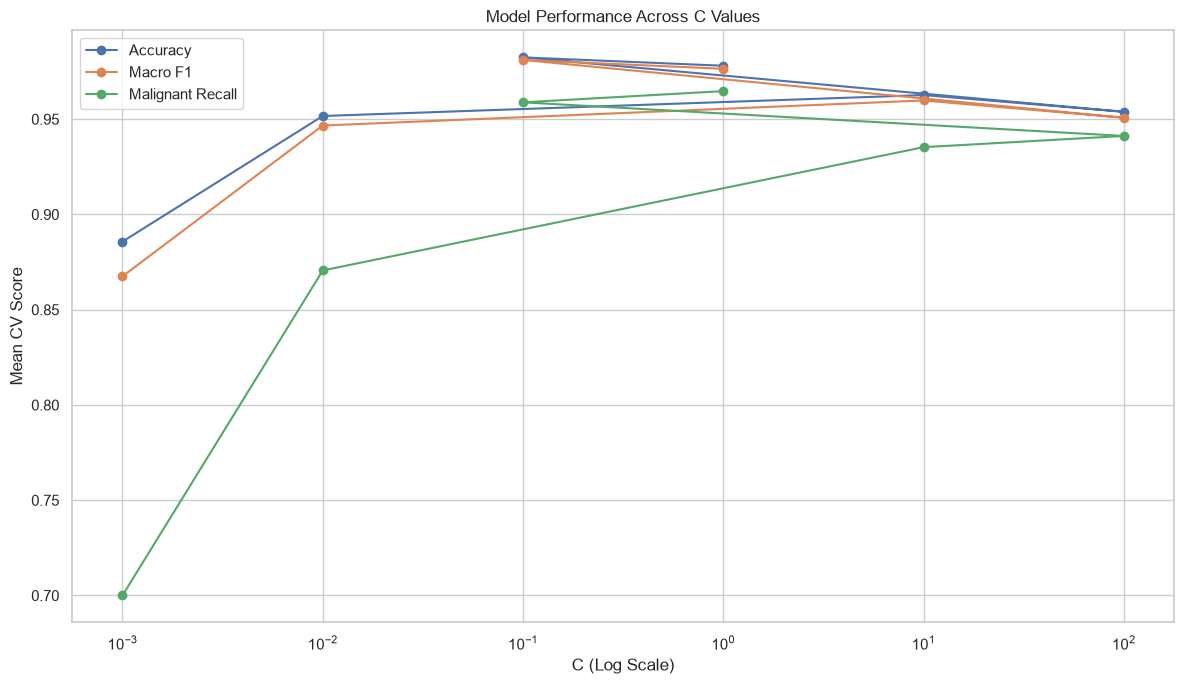

In [12]:
plt.figure(figsize=(12, 7))

plt.plot(
    results_df["param_model__C"].astype(float),
    results_df["mean_test_accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["param_model__C"].astype(float),
    results_df["mean_test_f1_macro"],
    marker="o",
    label="Macro F1"
)

plt.plot(
    results_df["param_model__C"].astype(float),
    results_df["mean_test_malignant_recall"],
    marker="o",
    label="Malignant Recall"
)

plt.xscale("log")

plt.title("Model Performance Across C Values")
plt.xlabel("C (Log Scale)")
plt.ylabel("Mean CV Score")

plt.legend()
plt.tight_layout()
plt.show()

In [15]:
best_model = grid_search.best_estimator_

In [16]:
y_pred = best_model.predict(X_test)


In [17]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["malignant", "benign"],
        digits=4
    )
)

              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



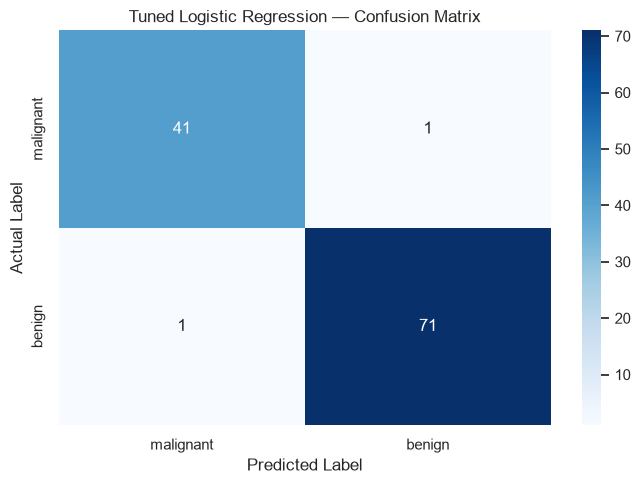

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["malignant", "benign"],
    yticklabels=["malignant", "benign"]
)

plt.title("Tuned Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [19]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)
tuned_predictions = best_model.predict(X_test)


def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro"
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro"
        ),
        "F1 (Macro)": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Malignant Recall": recall_score(
            y_true, y_pred, pos_label=0
        )
    }


baseline_metrics = calculate_metrics(
    y_test,
    baseline_predictions
)

tuned_metrics = calculate_metrics(
    y_test,
    tuned_predictions
)

comparison_df = pd.DataFrame(
    {
        "Baseline": baseline_metrics,
        "Tuned": tuned_metrics
    }
)

comparison_df

,Baseline,Tuned
Accuracy,0.982456,0.982456
Precision (Macro),0.981151,0.981151
Recall (Macro),0.981151,0.981151
F1 (Macro),0.981151,0.981151
Malignant Recall,0.976190,0.976190


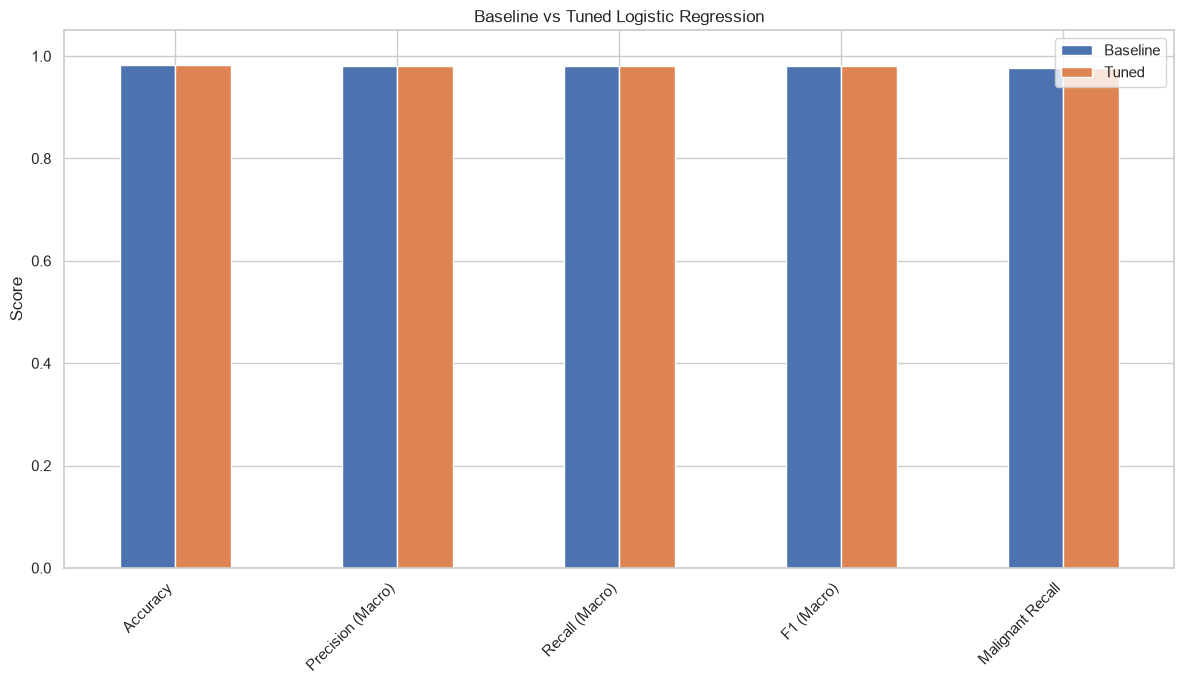

In [20]:
comparison_df.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Baseline vs Tuned Logistic Regression")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()